# ダミーデータによる協力性判定アルゴリズム（Chen et al. Algorithm 1）の検証

**目的**: Algorithm 1 が「2-pipe（クラスごとに道路を分けて走る）」と「1-pipe（混走）」を見分けられるかを、真値が分かっているダミーデータで調べる。

**このノートブックの考え方**
- Step 2〜6 が見ているのはスナップショットごとの `(ρ1, ρ2, ũ1, ũ2)` と名目速度関数だけで、**車線配置そのものは見ていない**。したがって「見た目の分離」がどう判定されるかは、真の名目速度関数と a2, b1（＝世界の設定）で事前に計算できる。
- そこで以下の3段で進める。
  1. **期待判定（事前計算）**: 世界パラメータとレーン配分から、どの状態が 2-pipe / 1-pipe / non-NE になる「べき」かを解析的に求める。
  2. **Tier A（マクロ直接生成）**: 真の regime・λ を埋め込んだ `(ρ, ũ)` を直接生成し、判定精度・eps/ノイズ感度・λ の回復性を測る（コードの正しさと同定可能性のテスト）。
  3. **Tier B（ミクロシミュレーション）**: 名目速度関数を平衡関係にもつ追従モデル＋車線変更ルールで **NGSIM形式（ft単位）の軌跡** を作り、既存パイプライン（`compute_macroscopic_data` 以降）にそのまま流す。

**ルール**: `src/` の関数は変更せず import して使う。変えたい処理はこのノートブック内で定義する。
（Step 1 の名目速度関数・a2・b1 はここでは「真値」を渡す。分離シナリオでは C-T/T-C 追従がほぼ無く a2, b1 を推定できないため、Step 1 と Step 2〜6 を切り離して検証する。）

In [1]:
import sys, os, io, time, contextlib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch

%load_ext autoreload
%autoreload 2

sys.path.append(os.path.abspath(".."))

from src.nominal_speed_func import (logistic_speed_density, logistic_density_speed,
                                    underwood_speed_density, underwood_density_speed)
from src.macroscopic_data import compute_macroscopic_data
from src.cooperation_surplus import (solve_1pipe_speed, compute_1pipe_speed_for_snapshots,
                                     compute_min_road_share, compute_cooperation_surplus)
from src.traffic_regime import (classify_traffic_regime, check_cooperation_existence,
                                estimate_surplus_split, predict_speed_with_lambda)

FT_TO_M = 0.3048
KM_TO_MILE = 1.60934

REGIMES = ['2-pipe', '1-pipe', 'non-NE']
REGIME_COLORS = {'2-pipe': 'tab:blue', '1-pipe': 'tab:green', 'non-NE': 'tab:red', 'undefined': 'lightgray'}

#src の関数は print が多いので、スイープ時は出力を捨てる
@contextlib.contextmanager
def quiet():
    with contextlib.redirect_stdout(io.StringIO()):
        yield

## 0. ダミー世界の設定（真値）

- 名目速度関数は論文 Table 4 の値（km/h, veh/km に換算）を「真の関数」として使う。
- スケーリングパラメータ a2, b1 は世界ごとに変える。
  - **penalty**（a2=b1=0.6）: 異クラスを追従すると同クラスより車間が広い → 混ぜると損 → s>0（分離に得がある世界）
  - **neutral**（a2=b1=1）: 誰を追従しても同じ → s≡0（分離しても得がない世界。偽陽性チェック用）
  - **paper**（Table 5: a2=0.4528, b1=2.5996）: 印刷版 Eq.7 では s<0（2-pipe は原理的に出ない）

In [2]:
CAR_PARAMS = {'ub': 7.93 * KM_TO_MILE, 'uf': 73.55 * KM_TO_MILE, 'rhoc': 20.40 / KM_TO_MILE,
              'theta1': 8.0387 / KM_TO_MILE, 'theta2': 0.2309}
TRUCK_PARAMS = {'uf': 42.55 * KM_TO_MILE, 'rhoc': 41.74 / KM_TO_MILE}

WORLDS = {
    'penalty': {'a2': 0.6,    'b1': 0.6},
    'neutral': {'a2': 1.0,    'b1': 1.0},
    'paper':   {'a2': 0.4528, 'b1': 2.5996},
}

#クラスi・先行車クラスjの名目速度 u_ij(rho) = u_i(rho / a_j)  (km/h)
def u_car(rho, a=1.0):
    return logistic_speed_density(np.asarray(rho, dtype=float) / a, **CAR_PARAMS)

def u_truck(rho, b=1.0):
    return underwood_speed_density(np.asarray(rho, dtype=float) / b, **TRUCK_PARAMS)

print(f"car  free speed u1(0) = {float(u_car(0.0)):.1f} km/h,  truck free speed u2(0) = {float(u_truck(0.0)):.1f} km/h")

car  free speed u1(0) = 116.5 km/h,  truck free speed u2(0) = 68.5 km/h


## 1. 期待判定（事前計算）

レーン配分で決まる道路シェア p2（トラック専用車線数 / 全車線数）を与えたとき、
各クラスの速度は ũ1 = u1(ρ1/(1−p2)), ũ2 = u2(ρ2/p2)。これを 1-pipe 速度 ū と比べれば、
アルゴリズムが返す「べき」判定が分かる（Eq.11）。

- 2-pipe になるのは p2 が **[p2\*, p2\* + s]** の帯に入るときだけ（黒実線〜黒破線の間）。
- 白点線は3車線での離散的な配分（トラック1車線: p2=1/3、2車線: p2=2/3）。

In [3]:
#neutral 世界では s が丸め誤差で ±1e-16 になるので、|s|<=S_TOL は s=0 とみなす
S_TOL = 1e-9

def theoretical_state(rho1, rho2, world):
    #印刷版Eq.7で ū を解き、p*, s を返す（src の solve_1pipe_speed をそのまま使用）
    w = WORLDS[world]
    try:
        ubar = solve_1pipe_speed(rho1, rho2, CAR_PARAMS, TRUCK_PARAMS, w['a2'], w['b1'])
    except ValueError:
        return np.nan, np.nan, np.nan, np.nan
    p1s = rho1 / logistic_density_speed(ubar, **CAR_PARAMS)
    p2s = rho2 / underwood_density_speed(ubar, **TRUCK_PARAMS)
    return ubar, p1s, p2s, 1.0 - p1s - p2s


def regime_from_speeds(u1, u2, ubar, eps):
    #classify_traffic_regime と同じ判定をスカラー/配列に対して行う
    du1, du2 = np.asarray(u1) - ubar, np.asarray(u2) - ubar
    eq = (np.abs(du1) <= eps) & (np.abs(du2) <= eps)
    ge = (du1 >= -eps) & (du2 >= -eps)
    return np.where(eq, '1-pipe', np.where(ge, '2-pipe', 'non-NE'))


def expected_regime_table(world, rho_tots, truck_share, p2_allocs, eps=1.0):
    rows = []
    for rt in rho_tots:
        r1, r2 = rt * (1 - truck_share), rt * truck_share
        ubar, p1s, p2s, s = theoretical_state(r1, r2, world)
        for p2 in p2_allocs:
            u1t, u2t = float(u_car(r1 / (1 - p2))), float(u_truck(r2 / p2))
            rows.append({
                'world': world, 'rho_tot': rt, 'truck_share': truck_share, 'p2_alloc': p2,
                'u_1pipe': ubar, 'p1_star': p1s, 'p2_star': p2s, 's': s,
                'u1_sep': u1t, 'u2_sep': u2t,
                'regime_expected': str(regime_from_speeds(u1t, u2t, ubar, eps)),
                #この配分を λ に読み替えた値（s>0 のときだけ意味がある）
                'lam_equiv': ((1 - p2) - p1s) / s if s > S_TOL else np.nan,
            })
    return pd.DataFrame(rows)


def plot_expected_regime_map(worlds=('penalty', 'neutral', 'paper'), truck_share=0.5,
                             rho_tots=np.arange(5, 61, 1.0), p2_grid=np.linspace(0.02, 0.98, 49),
                             eps=1.0, p2_marks=(1/3, 2/3)):
    code = {r: k for k, r in enumerate(REGIMES)}
    cmap = ListedColormap([REGIME_COLORS[r] for r in REGIMES])
    norm = BoundaryNorm([-0.5, 0.5, 1.5, 2.5], cmap.N)
    fig, axes = plt.subplots(1, len(worlds), figsize=(5 * len(worlds), 4.2), sharey=True)
    for ax, world in zip(np.atleast_1d(axes), worlds):
        tab = expected_regime_table(world, rho_tots, truck_share, p2_grid, eps)
        piv = tab.pivot(index='p2_alloc', columns='rho_tot', values='regime_expected').apply(lambda c: c.map(code))
        ax.pcolormesh(piv.columns, piv.index, piv.values.astype(float), cmap=cmap, norm=norm, shading='nearest')
        line = tab.drop_duplicates('rho_tot')
        ax.plot(line['rho_tot'], line['p2_star'], 'k-', lw=1.5)
        ax.plot(line['rho_tot'], line['p2_star'] + line['s'], 'k--', lw=1.5)
        for p in p2_marks:
            ax.axhline(p, color='white', lw=1.2, ls=':')
        ax.set_ylim(0, 1)
        ax.set_title(f"{world} (a2={WORLDS[world]['a2']}, b1={WORLDS[world]['b1']})")
        ax.set_xlabel('total density rho1+rho2 (veh/km/lane)')
    np.atleast_1d(axes)[0].set_ylabel('truck road share p2 (lane allocation)')
    handles = [Patch(color=REGIME_COLORS[r], label=r) for r in REGIMES]
    handles += [plt.Line2D([], [], color='k', label='p2*'), plt.Line2D([], [], color='k', ls='--', label='p2* + s'),
                plt.Line2D([], [], color='gray', ls=':', label='1 / 2 truck lanes of 3')]
    fig.legend(handles=handles, loc='upper center', ncol=6, bbox_to_anchor=(0.5, 1.06))
    fig.suptitle(f'Expected regime of a lane-separated state (truck share {truck_share:.0%}, eps={eps} km/h)', y=1.12)
    plt.tight_layout()
    plt.show()

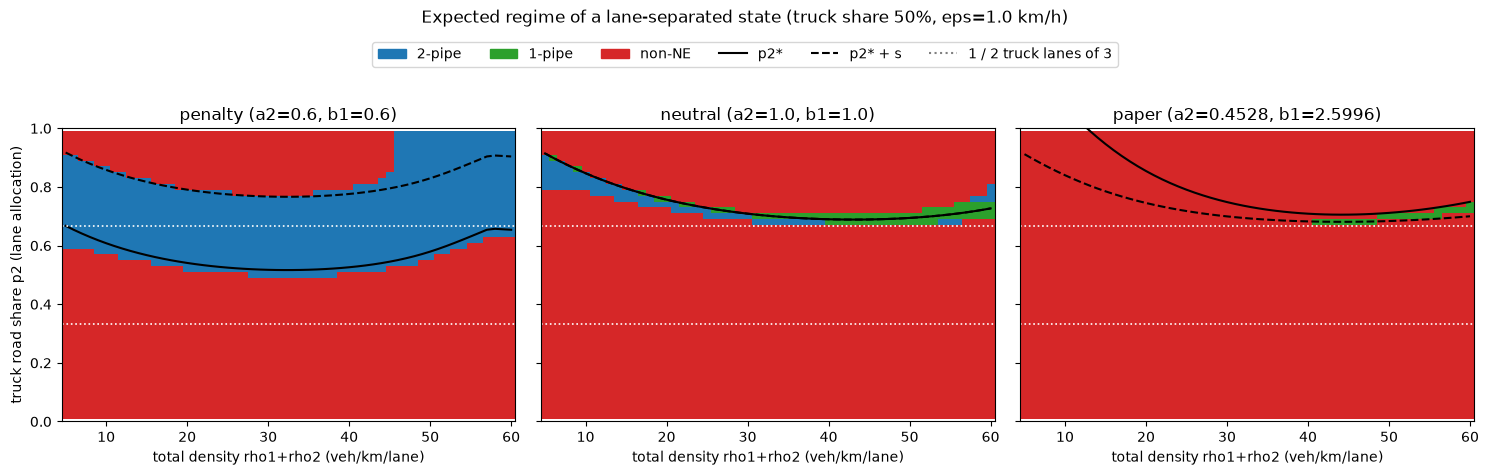

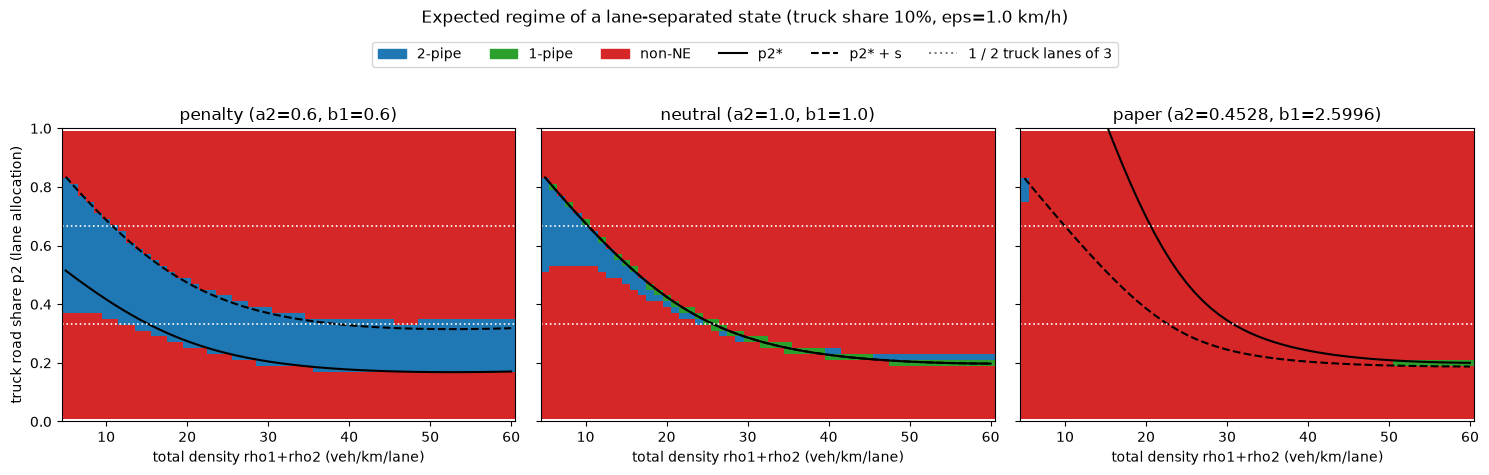

In [4]:
plot_expected_regime_map(truck_share=0.5)
plot_expected_regime_map(truck_share=0.1)

In [5]:
#3車線での離散配分（トラック1車線=1/3, 2車線=2/3）の期待判定一覧
exp_tab = pd.concat([expected_regime_table(w, [10, 20, 30, 40], 0.5, [1/3, 2/3]) for w in WORLDS])
exp_tab.round(3)

,world,rho_tot,truck_share,p2_alloc,u_1pipe,p1_star,p2_star,s,u1_sep,u2_sep,regime_expected,lam_equiv
0,penalty,10,0.5,0.333,49.874,0.142,0.608,0.250,111.216,38.404,non-NE,2.099
1,penalty,10,0.5,0.667,49.874,0.142,0.608,0.250,97.516,51.282,2-pipe,0.766
2,penalty,20,0.5,0.333,33.569,0.209,0.541,0.250,97.516,21.538,non-NE,1.830
3,penalty,20,0.5,0.667,33.569,0.209,0.541,0.250,59.840,38.404,2-pipe,0.497
4,penalty,30,0.5,0.333,22.391,0.233,0.517,0.250,77.824,12.079,non-NE,1.736
5,penalty,30,0.5,0.667,22.391,0.233,0.517,0.250,36.454,28.760,2-pipe,0.403
6,penalty,40,0.5,0.333,15.814,0.224,0.526,0.250,59.840,6.774,non-NE,1.771
7,penalty,40,0.5,0.667,15.814,0.224,0.526,0.250,24.609,21.538,2-pipe,0.438
0,neutral,10,0.5,0.333,54.536,0.153,0.847,0.000,111.216,38.404,non-NE,NaN
1,neutral,10,0.5,0.667,54.536,0.153,0.847,0.000,97.516,51.282,non-NE,NaN


## 2. Tier A: マクロ状態を直接生成して判定性能を測る

各スナップショット（0.5 s 間隔、15分 = 1800件）について、真の regime をブロック単位（30 s）で割り当てて速度を作る。

| 真の regime | 速度の作り方 |
|---|---|
| 2-pipe | p1 = p1\* + λ s, p2 = p2\* + (1−λ) s, ũi = ui(ρi/pi)（s>0 のときのみ。s≤0 なら 1-pipe に置換） |
| 1-pipe | ũ1 = ũ2 = ū |
| non-NE | 片方のクラスのシェアを pi\*·(1−κ), κ∈[0.15, 0.4] に押し込み、残りを相手に渡す |

その後、両クラスの速度に N(0, σ²) の観測ノイズを加える。出力は `compute_macroscopic_data` と同じ縦持ち形式なので、
`compute_1pipe_speed_for_snapshots` 以降をそのまま適用できる。

In [6]:
def generate_macro_states(world, n_snap=1800, truck_share=0.5, rho_range=(10, 60),
                          regime_probs=None, lam_true=0.7, noise_kmh=1.0, block=60,
                          seed=0, time_period=1):
    rng = np.random.default_rng(seed)
    if regime_probs is None:
        regime_probs = {'2-pipe': 0.4, '1-pipe': 0.3, 'non-NE': 0.3}
    names = list(regime_probs)
    probs = np.array([regime_probs[k] for k in names], dtype=float)
    probs /= probs.sum()

    #15分で「自由流→渋滞→自由流」を2往復する密度変動＋揺らぎ
    t = np.arange(n_snap)
    lo, hi = rho_range
    rho_tot = lo + (hi - lo) * 0.5 * (1 - np.cos(2 * np.pi * 2 * t / n_snap)) + rng.normal(0, 1.0, n_snap)
    rho_tot = np.clip(rho_tot, lo, hi)
    requested = np.repeat(rng.choice(names, size=int(np.ceil(n_snap / block)), p=probs), block)[:n_snap]

    rows, truth = [], []
    for k in range(n_snap):
        r1, r2 = rho_tot[k] * (1 - truck_share), rho_tot[k] * truck_share
        ubar, p1s, p2s, s = theoretical_state(r1, r2, world)
        reg = requested[k]
        if reg == '2-pipe' and not s > S_TOL:
            reg = '1-pipe'  #命題1: s<=0 では 2-pipe は存在しない
        lam, p1, p2 = np.nan, np.nan, np.nan
        if reg == '1-pipe':
            u1 = u2 = ubar
        elif reg == '2-pipe':
            lam = lam_true
            p1, p2 = p1s + lam * s, p2s + (1 - lam) * s
            u1, u2 = float(u_car(r1 / p1)), float(u_truck(r2 / p2))
        else:
            kappa = rng.uniform(0.15, 0.4)
            if rng.random() < 0.5:
                p1 = np.clip(p1s * (1 - kappa), 0.01, 0.99); p2 = 1 - p1
            else:
                p2 = np.clip(p2s * (1 - kappa), 0.01, 0.99); p1 = 1 - p2
            u1, u2 = float(u_car(r1 / p1)), float(u_truck(r2 / p2))
        u1 += rng.normal(0, noise_kmh)
        u2 += rng.normal(0, noise_kmh)
        gt = k * 500
        rows.append({'time_period': time_period, 'Global_Time': gt, 'v_Class': 2, 'density_veh_km': r1, 'speed_kmh': u1})
        rows.append({'time_period': time_period, 'Global_Time': gt, 'v_Class': 3, 'density_veh_km': r2, 'speed_kmh': u2})
        truth.append({'time_period': time_period, 'Global_Time': gt, 'regime_true': reg, 'lam_true': lam,
                      'p1_true': p1, 'p2_true': p2, 's_true': s, 'u_1pipe_true': ubar})
    return pd.DataFrame(rows), pd.DataFrame(truth)


def run_algorithm(df_macro, world, eps_kmh=2.0, verbose=False):
    #Step 3〜5 を src の関数で実行（Step 1 の結果としては真値を渡す）
    w = WORLDS[world]
    ctx = contextlib.nullcontext() if verbose else quiet()
    with ctx:
        d = compute_1pipe_speed_for_snapshots(df_macro, CAR_PARAMS, TRUCK_PARAMS, w['a2'], w['b1'])
        d = compute_min_road_share(d, CAR_PARAMS, TRUCK_PARAMS)
        d = compute_cooperation_surplus(d)
        d = classify_traffic_regime(d, eps_kmh)
        d = check_cooperation_existence(d)
    return d


def evaluate_regime(df_pred, df_truth):
    m = df_pred.merge(df_truth, on=['time_period', 'Global_Time'])
    cm = (pd.crosstab(m['regime_true'], m['regime'], normalize='index')
            .reindex(index=REGIMES, columns=REGIMES + ['undefined'], fill_value=0))
    metrics = {'accuracy': (m['regime'] == m['regime_true']).mean(),
               'pcoop_pred': (m['regime'] == '2-pipe').mean(),
               'pcoop_true': (m['regime_true'] == '2-pipe').mean()}
    return m, cm, metrics


def plot_confusion(cm, title=''):
    fig, ax = plt.subplots(figsize=(5.2, 3.6))
    ax.imshow(cm.values, cmap='Blues', vmin=0, vmax=1)
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, f'{cm.values[i, j]:.2f}', ha='center', va='center',
                    color='white' if cm.values[i, j] > 0.5 else 'black')
    ax.set_xticks(range(cm.shape[1]), cm.columns)
    ax.set_yticks(range(cm.shape[0]), cm.index)
    ax.set_xlabel('predicted (Algorithm 1)')
    ax.set_ylabel('true')
    ax.set_title(title)
    plt.tight_layout()
    plt.show()


def plot_du_scatter(m, eps_kmh, title=''):
    #横軸 ũ1-ū, 縦軸 ũ2-ū。真の regime で色分け。点線の枠が 1-pipe 判定領域
    fig, ax = plt.subplots(figsize=(5.5, 5))
    for r in REGIMES:
        d = m[m['regime_true'] == r]
        ax.scatter(d['du1'], d['du2'], s=6, alpha=0.5, color=REGIME_COLORS[r], label=f'true {r}')
    ax.axvline(-eps_kmh, color='k', lw=0.8, ls=':')
    ax.axhline(-eps_kmh, color='k', lw=0.8, ls=':')
    ax.plot([-eps_kmh, eps_kmh, eps_kmh, -eps_kmh, -eps_kmh], [-eps_kmh, -eps_kmh, eps_kmh, eps_kmh, -eps_kmh], 'k--', lw=0.8)
    ax.set_xlabel('u1_obs - u* (km/h)')
    ax.set_ylabel('u2_obs - u* (km/h)')
    ax.set_title(title)
    ax.legend(markerscale=3)
    ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

### A-1. 基準ケース: penalty 世界・1:1・ノイズ 1 km/h・eps 2 km/h

1-pipe速度を計算: 1,800スナップショット中、1,800件で解を取得
最小道路占有を計算: 1,800スナップショット中、1,800件で計算完了
協力余剰sを計算: 1,800スナップショット中、1,800件で計算完了（うちs>0: 1,800件）
交通状態を判定(eps=2.0 km/h): 判定対象 1,800件 (対象外 undefined: 0件)
      2-pipe: 1,037件 (57.61%)
      1-pipe: 432件 (24.00%)
      non-NE: 331件 (18.39%)
  Pcoop = 57.61% (論文: 13.83%)
  平均s: 2-pipe = 0.2500, 1-pipe = 0.2500 (論文: 0.15, 0.11)
協力性の存在判定: 判定対象 1,800件
  s>0             : 1,800件 (100.00%)
  2-pipe          : 1,037件 (57.61%)  ← 論文Pcoop=13.83%
  2-pipe かつ s>0 : 1,037件 (57.61%)  ← 協力性あり(Step6で使う)
  2-pipe かつ s<=0: 0件 (0.00% of 2-pipe)  ← 命題1と不整合
{'accuracy': np.float64(0.8988888888888888), 'pcoop_pred': np.float64(0.5761111111111111), 'pcoop_true': np.float64(0.5333333333333333)}


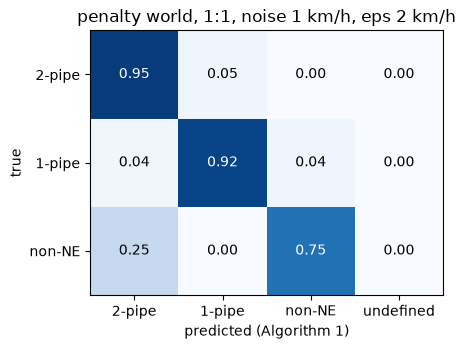

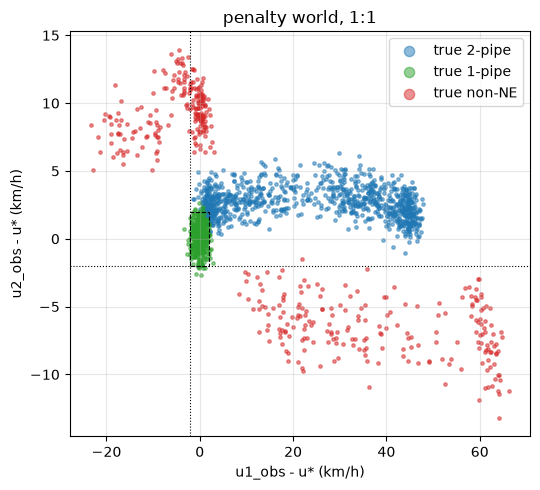

In [7]:
EPS = 2.0
df_macro_A, truth_A = generate_macro_states('penalty', truck_share=0.5, lam_true=0.7, noise_kmh=1.0, seed=0)
res_A = run_algorithm(df_macro_A, 'penalty', eps_kmh=EPS, verbose=True)
m_A, cm_A, met_A = evaluate_regime(res_A, truth_A)
print(met_A)
plot_confusion(cm_A, 'penalty world, 1:1, noise 1 km/h, eps 2 km/h')
plot_du_scatter(m_A, EPS, 'penalty world, 1:1')

In [8]:
#s の真値と推定値の一致（Step 3 は真値パラメータなので一致するはず＝コード検証）
print('max |s - s_true| =', np.nanmax(np.abs(m_A['s'] - m_A['s_true'])))
print('max |u* - u*_true| =', np.nanmax(np.abs(m_A['u_1pipe'] - m_A['u_1pipe_true'])))

#λ の推定（Step 6）
with quiet():
    est_A = estimate_surplus_split(res_A, CAR_PARAMS, TRUCK_PARAMS)
print(f"lambda_true = 0.7,  lambda_hat = {est_A['lambda_hat']:.4f},  "
      f"CV = {est_A['cv']['lambda'].mean():.4f} ± {est_A['cv']['lambda'].std():.4f}")

max |s - s_true| = 0.0
max |u* - u*_true| = 0.0


lambda_true = 0.7,  lambda_hat = 0.6745,  CV = 0.6744 ± 0.0016


### A-2. 偽陽性チェック: neutral 世界（s≡0）

neutral 世界では 2-pipe を作れないので、真の状態は 1-pipe と non-NE だけ。
ここで 2-pipe 判定や `coop_exists` が出たらそれは偽陽性。
※ s は数値的に ±1e-16 程度になり、src の `check_cooperation_existence` は `s > 0` で判定しているので、`coop_exists` は丸め誤差で揺れる（これ自体が実装上の注意点）。

{'accuracy': np.float64(0.9088888888888889), 'pcoop_pred': np.float64(0.04722222222222222), 'pcoop_true': np.float64(0.0)}
s range: -3.5860203695392556e-14 3.3861802251067274e-14  coop_exists rate: 0.018333333333333333


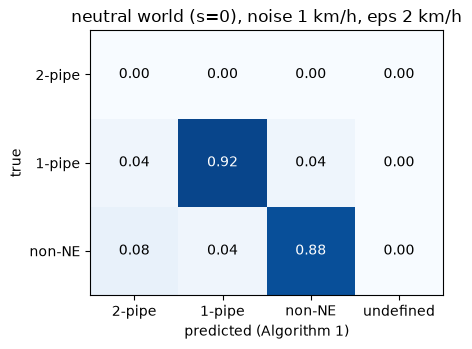

In [9]:
df_macro_N, truth_N = generate_macro_states('neutral', truck_share=0.5, noise_kmh=1.0, seed=1)
res_N = run_algorithm(df_macro_N, 'neutral', eps_kmh=EPS)
m_N, cm_N, met_N = evaluate_regime(res_N, truth_N)
print(met_N)
print('s range:', res_N['s'].min(), res_N['s'].max(), ' coop_exists rate:', res_N['coop_exists'].mean())
plot_confusion(cm_N, 'neutral world (s=0), noise 1 km/h, eps 2 km/h')

### A-3. eps × ノイズ感度

u\*・p\*・s は eps に依存しないので、Step 3 まで1回計算して eps だけ変えて判定し直す。
- 判定精度（accuracy）と、推定 Pcoop / 真の Pcoop を比較する。
- 実データで「Pcoop が数 km/h のズレで大きく振れる」現象が、真値ありの条件でどの程度起きるかを見る。

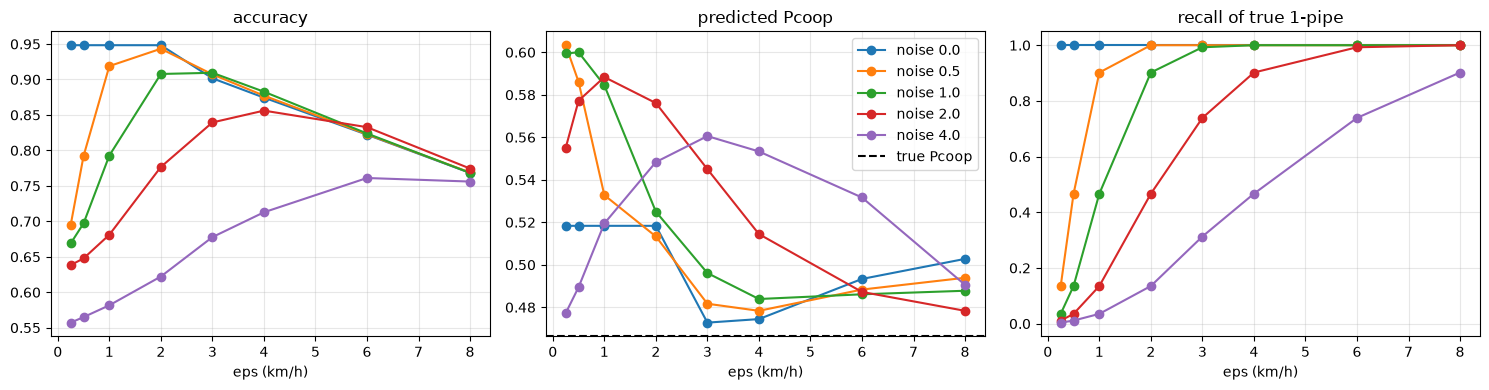

noise,0.0,0.5,1.0,2.0,4.0
eps,,,,,
0.25,0.948,0.695,0.669,0.638,0.557
0.50,0.948,0.792,0.697,0.648,0.565
1.00,0.948,0.919,0.793,0.681,0.582
2.00,0.948,0.943,0.908,0.777,0.622
3.00,0.902,0.907,0.909,0.839,0.678
4.00,0.874,0.877,0.883,0.856,0.713
6.00,0.822,0.823,0.824,0.833,0.761
8.00,0.768,0.769,0.768,0.774,0.756


In [10]:
eps_grid = [0.25, 0.5, 1, 2, 3, 4, 6, 8]
noise_grid = [0.0, 0.5, 1.0, 2.0, 4.0]
rows = []
for noise in noise_grid:
    dfm, tr = generate_macro_states('penalty', truck_share=0.5, lam_true=0.7, noise_kmh=noise, seed=10)
    w = WORLDS['penalty']
    with quiet():
        d_s = compute_cooperation_surplus(compute_min_road_share(
            compute_1pipe_speed_for_snapshots(dfm, CAR_PARAMS, TRUCK_PARAMS, w['a2'], w['b1']),
            CAR_PARAMS, TRUCK_PARAMS))
    for eps in eps_grid:
        with quiet():
            d_r = classify_traffic_regime(d_s, eps)
        _, cm, met = evaluate_regime(d_r, tr)
        rows.append({'noise': noise, 'eps': eps, **met,
                     'recall_2pipe': cm.loc['2-pipe', '2-pipe'], 'recall_1pipe': cm.loc['1-pipe', '1-pipe'],
                     'recall_nonNE': cm.loc['non-NE', 'non-NE']})
sens_A = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for noise, g in sens_A.groupby('noise'):
    axes[0].plot(g['eps'], g['accuracy'], marker='o', label=f'noise {noise}')
    axes[1].plot(g['eps'], g['pcoop_pred'], marker='o', label=f'noise {noise}')
    axes[2].plot(g['eps'], g['recall_1pipe'], marker='o', label=f'noise {noise}')
axes[1].axhline(sens_A['pcoop_true'].iloc[0], color='k', ls='--', label='true Pcoop')
for ax, t in zip(axes, ['accuracy', 'predicted Pcoop', 'recall of true 1-pipe']):
    ax.set_xlabel('eps (km/h)'); ax.set_title(t); ax.grid(alpha=0.3)
axes[1].legend()
plt.tight_layout()
plt.show()
sens_A.pivot(index='eps', columns='noise', values='accuracy').round(3)

### A-4. λ の回復性 × トラック比率

1:1 は λ の効きが最大になる条件。NGSIM に近い低トラック比率でも λ が回復できるかを見る。
`leverage` は λ を 0→1 に動かしたときの予測速度の変化幅（km/h、2-pipe 行の平均）で、これがノイズより小さいと λ は同定できない。

In [11]:
def lambda_leverage(df_coop):
    d = df_coop[df_coop['coop_exists']]
    u1_0, u2_0 = predict_speed_with_lambda(d, 0.0, CAR_PARAMS, TRUCK_PARAMS)
    u1_1, u2_1 = predict_speed_with_lambda(d, 1.0, CAR_PARAMS, TRUCK_PARAMS)
    return float(np.mean(np.abs(u1_1 - u1_0))), float(np.mean(np.abs(u2_1 - u2_0)))

rows = []
for share in [0.05, 0.1, 0.25, 0.5]:
    for lam_true in [0.2, 0.5, 0.8]:
        dfm, tr = generate_macro_states('penalty', truck_share=share, lam_true=lam_true, noise_kmh=1.0, seed=20)
        d = run_algorithm(dfm, 'penalty', eps_kmh=EPS)
        try:
            with quiet():
                est = estimate_surplus_split(d, CAR_PARAMS, TRUCK_PARAMS)
            lam_hat, lam_cv_sd = est['lambda_hat'], est['cv']['lambda'].std()
        except ValueError:
            lam_hat, lam_cv_sd = np.nan, np.nan
        lev1, lev2 = lambda_leverage(d)
        rows.append({'truck_share': share, 'lam_true': lam_true, 'lam_hat': lam_hat, 'cv_sd': lam_cv_sd,
                     'n_coop': int(d['coop_exists'].sum()), 's_mean_2pipe': d.loc[d['coop_exists'], 's'].mean(),
                     'leverage_car': lev1, 'leverage_truck': lev2})
lam_A = pd.DataFrame(rows)
lam_A['abs_err'] = (lam_A['lam_hat'] - lam_A['lam_true']).abs()
lam_A.round(3)

,truck_share,lam_true,lam_hat,cv_sd,n_coop,s_mean_2pipe,leverage_car,leverage_truck,abs_err
0,0.05,0.2,0.427,0.007,647,0.134,10.780,9.775,0.227
1,0.05,0.5,0.612,0.004,647,0.134,10.780,9.775,0.112
2,0.05,0.8,0.837,0.002,647,0.134,10.780,9.775,0.037
3,0.10,0.2,0.318,0.007,608,0.175,13.455,11.243,0.118
4,0.10,0.5,0.545,0.006,608,0.175,13.455,11.243,0.045
5,0.10,0.8,0.806,0.004,608,0.175,13.455,11.243,0.006
6,0.25,0.2,0.202,0.005,640,0.244,18.615,11.728,0.002
7,0.25,0.5,0.465,0.004,640,0.244,18.615,11.728,0.035
8,0.25,0.8,0.733,0.004,640,0.244,18.615,11.728,0.067
9,0.50,0.2,0.186,0.001,658,0.250,23.721,8.403,0.014


## 3. Tier B: リング道路ミクロシミュレーション → NGSIM形式の軌跡

**追従モデル**（1次の最適速度型）:
dv/dt = (V_ij(spacing) − v)/τ + ノイズ,  V_ij(spacing) = u_i(ρ/a_j),  ρ = 1000/spacing [veh/km]

- 平衡状態ではクラスペアごとの名目速度関数をそのまま満たすので、Step 1 の「真の関数」が定義どおりになる。
- ランダム混合・定常状態では、全車両の平衡車間の和＝車線長 から **印刷版 Eq.7 の ū** が導かれる（1-pipe の理論と整合）。
- 衝突防止に安全速度 (gap − s0)/T を上限として入れている（高密度でのみ効く）。

**車線ルール（policy）**（車線は NGSIM に合わせて Lane_ID 2,3,4）

| policy | 車 | トラック | 車線変更 | 想定 |
|---|---|---|---|---|
| `mixed_nolc` | 2,3,4 | 2,3,4 | なし | 混走・追い越し不可 |
| `mixed_lc` | 2,3,4 | 2,3,4 | あり | 混走・追い越し可 |
| `sep_1lane` | 2,3 | 4 | あり | 分離（トラック1車線, p2=1/3） |
| `sep_2lane` | 2 | 3,4 | あり | 分離（トラック2車線, p2=2/3） |

**リング道路**（周長 1090 m）にした理由: 密度を厳密に固定でき、NGSIM のような空の状態からの立ち上がり（ウォームアップ）が無いため。
観測区間は先頭 545 m（NGSIM I-80 と同程度）で、この区間内の車両だけを記録する。
※ 同じ車両がリングを周回して何度も区間に入るため、`Vehicle_ID` は区間に入るたびに途切れた系列になる（ペア処理では `max_gap_frames` で分かれる）。

In [12]:
CAR_LEN_M, TRUCK_LEN_M = 4.5, 12.0
CAR_WID_M, TRUCK_WID_M = 1.8, 2.6
S0_M = 2.0          #停止時の最小車間（バンパー間, m）
T_SAFE_S = 0.8      #安全速度の時間ヘッドウェイ（s）
LANE_WIDTH_FT = 12.0
LC_INTERVAL_S = 1.0 #車線変更を検討する間隔
LC_COOLDOWN_S = 5.0 #車線変更後、次の変更までの待ち時間
LC_GAIN_KMH = 3.0   #車線変更する最小の速度利得

NGSIM_COLUMNS = ['Vehicle_ID', 'Frame_ID', 'Total_Frames', 'Global_Time', 'Local_X', 'Local_Y',
                 'Global_X', 'Global_Y', 'v_Length', 'v_Width', 'v_Class', 'v_Vel', 'v_Acc',
                 'Lane_ID', 'Preceding', 'Following', 'Space_Headway', 'Time_Headway']


def lane_policy(policy, lanes):
    lanes = list(lanes)
    table = {
        'mixed_nolc': (lanes, lanes, False),
        'mixed_lc':   (lanes, lanes, True),
        'sep_1lane':  (lanes[:-1], lanes[-1:], True),
        'sep_2lane':  (lanes[:1], lanes[1:], True),
    }
    return table[policy]


def eq_speed_ms(ego_truck, lead_truck, spacing_m, world):
    #平衡速度 V_ij(spacing) [m/s]。車は先行がトラックなら a2、トラックは先行が車なら b1
    w = WORLDS[world]
    rho = 1000.0 / np.maximum(spacing_m, 0.1)
    a = np.where(lead_truck, w['a2'], 1.0)
    b = np.where(lead_truck, 1.0, w['b1'])
    v_kmh = np.where(ego_truck, u_truck(rho, b), u_car(rho, a))
    return v_kmh / 3.6


def target_speed_ms(ego_truck, lead_truck, spacing_m, lead_len_m, world):
    v_eq = eq_speed_ms(ego_truck, lead_truck, spacing_m, world)
    v_safe = np.maximum(0.0, (spacing_m - lead_len_m - S0_M) / T_SAFE_S)
    return np.minimum(v_eq, v_safe)


def find_leaders(x, lane, ring_m):
    #同一車線内の先行車インデックス(-1=なし)と車頭間隔(front-to-front, m)
    n = len(x)
    lead = np.full(n, -1)
    spacing = np.full(n, ring_m)
    for l in np.unique(lane):
        idx = np.flatnonzero(lane == l)
        if len(idx) < 2:
            continue
        order = idx[np.argsort(x[idx])]
        nxt = np.roll(order, -1)
        lead[order] = nxt
        spacing[order] = (x[nxt] - x[order]) % ring_m
    return lead, spacing


def _neighbors_in_lane(i, l, x, lane, ring_m):
    idx = np.flatnonzero(lane == l)
    idx = idx[idx != i]
    if len(idx) == 0:
        return -1, ring_m, -1, ring_m
    d_f = (x[idx] - x[i]) % ring_m
    d_b = (x[i] - x[idx]) % ring_m
    kf, kb = np.argmin(d_f), np.argmin(d_b)
    return idx[kf], d_f[kf], idx[kb], d_b[kb]


def _target_single(i, jf, sp_f, is_truck, length, world):
    lt = bool(is_truck[jf]) if jf >= 0 else False
    ll = length[jf] if jf >= 0 else 0.0
    return float(target_speed_ms(np.array([is_truck[i]]), np.array([lt]), np.array([sp_f]), np.array([ll]), world)[0])


def try_lane_changes(x, v, lane, is_truck, length, allowed, world, ring_m, rng, cooldown):
    #隣接車線の方が目標速度が LC_GAIN_KMH 以上高く、前後の車間が安全なら車線変更（ランダム順に逐次処理）
    n_changes = 0
    gain_th = LC_GAIN_KMH / 3.6
    for i in rng.permutation(len(x)):
        if cooldown[i] > 0:
            continue
        cands = [l for l in (lane[i] - 1, lane[i] + 1) if l in allowed[bool(is_truck[i])]]
        if not cands:
            continue
        jf, sp_f, _, _ = _neighbors_in_lane(i, lane[i], x, lane, ring_m)
        v_cur = _target_single(i, jf, sp_f, is_truck, length, world)
        best_l, best_gain = None, gain_th
        for l in cands:
            jf2, sp_f2, jb2, sp_b2 = _neighbors_in_lane(i, l, x, lane, ring_m)
            gap_f = sp_f2 - (length[jf2] if jf2 >= 0 else 0.0)
            gap_b = sp_b2 - length[i]
            v_back = v[jb2] if jb2 >= 0 else 0.0
            if gap_f < S0_M + 0.5 * v[i] or gap_b < S0_M + 1.0 * v_back:
                continue
            gain = _target_single(i, jf2, sp_f2, is_truck, length, world) - v_cur
            if gain > best_gain:
                best_l, best_gain = l, gain
        if best_l is not None:
            lane[i] = best_l
            cooldown[i] = LC_COOLDOWN_S
            n_changes += 1
    return n_changes

In [13]:
def simulate_ring_road(world, rho_tot, truck_share=0.5, policy='mixed_lc', lanes=(2, 3, 4),
                       ring_m=1090.0, section_m=545.0, duration_s=900.0, warmup_s=300.0,
                       dt=0.1, tau_s=0.5, acc_noise=0.1, record_every=1, time_period=1,
                       seed=0, verbose=True):
    #rho_tot: 全体密度 (veh/km/lane)。戻り値は NGSIM と同じ列・単位(ft, ft/s)の DataFrame + time_period
    rng = np.random.default_rng(seed)
    car_lanes, truck_lanes, lc_on = lane_policy(policy, lanes)
    allowed = {False: set(car_lanes), True: set(truck_lanes)}
    n_l = len(lanes)
    n_car = int(round(rho_tot * (1 - truck_share) * ring_m / 1000 * n_l))
    n_trk = int(round(rho_tot * truck_share * ring_m / 1000 * n_l))
    n = n_car + n_trk
    is_truck = np.r_[np.zeros(n_car, bool), np.ones(n_trk, bool)]
    length = np.where(is_truck, TRUCK_LEN_M, CAR_LEN_M)
    width = np.where(is_truck, TRUCK_WID_M, CAR_WID_M)

    #初期配置: 混走は全車両をランダムに各車線へ、分離はクラスごとに許可車線へ均等に割り当て
    lane = np.zeros(n, dtype=int)
    if set(car_lanes) == set(truck_lanes):
        ids = rng.permutation(n)
        lane[ids] = np.array(lanes)[np.arange(n) % n_l]
    else:
        for cls, al in ((False, car_lanes), (True, truck_lanes)):
            ids = rng.permutation(np.flatnonzero(is_truck == cls))
            lane[ids] = np.array(al)[np.arange(len(ids)) % len(al)]
    x = np.zeros(n)
    for l in lanes:
        idx = rng.permutation(np.flatnonzero(lane == l))
        if len(idx) == 0:
            continue
        h = ring_m / len(idx)
        x[idx] = np.arange(len(idx)) * h + rng.uniform(-0.05, 0.05, len(idx)) * h
    x %= ring_m

    def _targets(lead, spacing):
        has = lead >= 0
        lt = np.where(has, is_truck[np.maximum(lead, 0)], False)
        ll = np.where(has, length[np.maximum(lead, 0)], 0.0)
        return target_speed_ms(is_truck, lt, spacing, ll, world)

    lead, spacing = find_leaders(x, lane, ring_m)
    v = _targets(lead, spacing)
    cooldown = np.zeros(n)
    n_warm = int(round(warmup_s / dt))
    n_total = n_warm + int(round(duration_s / dt))
    lc_every = int(round(LC_INTERVAL_S / dt))
    rec, n_lc = [], 0

    for step in range(n_total):
        if lc_on and step % lc_every == 0:
            cooldown = np.maximum(cooldown - LC_INTERVAL_S, 0.0)
            n_lc += try_lane_changes(x, v, lane, is_truck, length, allowed, world, ring_m, rng, cooldown)
            lead, spacing = find_leaders(x, lane, ring_m)

        target = _targets(lead, spacing)
        acc = np.clip((target - v) / tau_s + rng.normal(0, acc_noise, n), -7.0, 3.0)
        v_new = np.maximum(v + acc * dt, 0.0)
        gap = spacing - np.where(lead >= 0, length[np.maximum(lead, 0)], 0.0)
        v_new = np.minimum(v_new, np.maximum(gap - 0.5, 0.0) / dt)  #衝突防止のハードガード
        acc = (v_new - v) / dt
        x = (x + v_new * dt) % ring_m
        v = v_new
        lead, spacing = find_leaders(x, lane, ring_m)

        if step >= n_warm and (step - n_warm) % record_every == 0:
            frame = step - n_warm
            ids = np.flatnonzero(x < section_m)
            follower = np.full(n, -1)
            has = lead >= 0
            follower[lead[has]] = np.flatnonzero(has)
            sp = np.where(lead[ids] >= 0, spacing[ids], 0.0)
            rec.append(np.column_stack([
                ids + 1,                                           # Vehicle_ID
                np.full(len(ids), frame + 1),                      # Frame_ID
                np.zeros(len(ids)),                                # Total_Frames (後で計算)
                np.full(len(ids), round(frame * dt * 1000)),       # Global_Time (ms)
                (lane[ids] - 0.5) * LANE_WIDTH_FT,                 # Local_X (ft)
                x[ids] / FT_TO_M,                                  # Local_Y (ft)
                (lane[ids] - 0.5) * LANE_WIDTH_FT,                 # Global_X
                x[ids] / FT_TO_M,                                  # Global_Y
                length[ids] / FT_TO_M,                             # v_Length (ft)
                width[ids] / FT_TO_M,                              # v_Width (ft)
                np.where(is_truck[ids], 3, 2),                     # v_Class
                v[ids] / FT_TO_M,                                  # v_Vel (ft/s)
                acc[ids] / FT_TO_M,                                # v_Acc (ft/s^2)
                lane[ids],                                         # Lane_ID
                lead[ids] + 1,                                     # Preceding (0=なし)
                follower[ids] + 1,                                 # Following (0=なし)
                sp / FT_TO_M,                                      # Space_Headway (ft)
                np.where(v[ids] > 0.01, sp / np.maximum(v[ids], 0.01), 9999.99),  # Time_Headway (s)
            ]))

    df = pd.DataFrame(np.vstack(rec), columns=NGSIM_COLUMNS)
    int_cols = ['Vehicle_ID', 'Frame_ID', 'Global_Time', 'v_Class', 'Lane_ID', 'Preceding', 'Following']
    df[int_cols] = df[int_cols].astype(int)
    df['Total_Frames'] = df.groupby('Vehicle_ID')['Frame_ID'].transform('size').astype(int)
    df['time_period'] = time_period
    if verbose:
        spd = df.groupby('v_Class')['v_Vel'].mean() * FT_TO_M * 3.6
        print(f"[{world}, rho={rho_tot}, truck={truck_share:.0%}, {policy}] cars {n_car}, trucks {n_trk}, "
              f"lane changes {n_lc}, rows {len(df):,}, mean speed car {spd.get(2, np.nan):.1f} / "
              f"truck {spd.get(3, np.nan):.1f} km/h")
    return df

In [14]:
def plot_time_space(df_traj, t_window=(0, 180), title='', every_n_frames=5):
    lanes = sorted(df_traj['Lane_ID'].unique())
    t = df_traj['Global_Time'] / 1000
    d = df_traj[(t >= t_window[0]) & (t <= t_window[1]) & (df_traj['Frame_ID'] % every_n_frames == 0)]
    fig, axes = plt.subplots(1, len(lanes), figsize=(5 * len(lanes), 3.8), sharey=True)
    for ax, l in zip(np.atleast_1d(axes), lanes):
        dl = d[d['Lane_ID'] == l]
        for cls, color, label, s in ((2, 'tab:gray', 'car', 1), (3, 'tab:orange', 'truck', 2)):
            dc = dl[dl['v_Class'] == cls]
            ax.scatter(dc['Global_Time'] / 1000, dc['Local_Y'] * FT_TO_M, s=s, color=color, label=label)
        ax.set_title(f'Lane {l}')
        ax.set_xlabel('time (s)')
    np.atleast_1d(axes)[0].set_ylabel('position (m)')
    np.atleast_1d(axes)[0].legend(markerscale=5, loc='upper right')
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


def plot_micro_check(df_traj, world, max_points=4000, seed=0):
    #ミクロ密度(1000/spacing)と速度の散布図に、真の u_ij を重ねる（シミュレータが名目関数に従うかの確認）
    cls_map = df_traj.groupby('Vehicle_ID')['v_Class'].first()
    d = df_traj[df_traj['Preceding'] > 0].copy()
    d['lead_class'] = d['Preceding'].map(cls_map)
    d['rho_micro'] = 1000 / (d['Space_Headway'] * FT_TO_M)
    d['u_kmh'] = d['v_Vel'] * FT_TO_M * 3.6
    w = WORLDS[world]
    rho = np.linspace(1, 120, 300)
    modes = [((2, 2), 'C-C', u_car(rho)), ((2, 3), 'C-T', u_car(rho, w['a2'])),
             ((3, 3), 'T-T', u_truck(rho)), ((3, 2), 'T-C', u_truck(rho, w['b1']))]
    fig, axes = plt.subplots(1, 4, figsize=(18, 3.8), sharey=True)
    for ax, ((ego, ld), name, curve) in zip(axes, modes):
        dm = d[(d['v_Class'] == ego) & (d['lead_class'] == ld)]
        if len(dm) > max_points:
            dm = dm.sample(max_points, random_state=seed)
        ax.scatter(dm['rho_micro'], dm['u_kmh'], s=2, alpha=0.3)
        ax.plot(rho, curve, 'r-', lw=1.5, label='true u_ij')
        ax.set_title(f'{name} (n={len(dm):,})')
        ax.set_xlabel('micro density 1000/spacing (veh/km)')
        ax.set_xlim(0, 120)
    axes[0].set_ylabel('speed (km/h)')
    axes[0].legend()
    plt.tight_layout()
    plt.show()


def analyze_sim(df_traj, world, eps_kmh=2.0, section_m=545.0, lanes=(2, 3, 4), verbose=False):
    #NGSIM と同じ手順: compute_macroscopic_data → Step 3〜5。L_m は明示的に渡す
    ctx = contextlib.nullcontext() if verbose else quiet()
    with ctx:
        df_macro = compute_macroscopic_data(df_traj, lanes=lanes, classes=(2, 3), L_m=section_m, n_lanes=len(lanes))
    return df_macro, run_algorithm(df_macro, world, eps_kmh, verbose)


def summarize_regime(d):
    j = d[d['regime'] != 'undefined']
    out = j['regime'].value_counts(normalize=True).reindex(REGIMES, fill_value=0).to_dict()
    out.update({'n_snap': len(j), 'coop_exists': j['coop_exists'].mean(), 's_mean': j['s'].mean(),
                'rho1': j['rho1'].mean(), 'rho2': j['rho2'].mean(),
                'u1_obs': j['u1_obs'].mean(), 'u2_obs': j['u2_obs'].mean(), 'u_1pipe': j['u_1pipe'].mean(),
                'du1_med': j['du1'].median(), 'du2_med': j['du2'].median()})
    return out

### B-1. 代表ケース: penalty 世界・ρ=30 veh/km/lane・1:1・4つの車線ルール（10 Hz, 15分）

まず時空間図で「見た目」を確認し、ミクロの速度-密度が真の名目関数に乗っていることを確かめてから、判定結果を期待判定と比べる。

In [15]:
B1_WORLD, B1_RHO, B1_SHARE = 'penalty', 30, 0.5
POLICY_LIST = ['mixed_nolc', 'mixed_lc', 'sep_1lane', 'sep_2lane']
sims_B1 = {}
for k, pol in enumerate(POLICY_LIST, start=1):
    t0 = time.time()
    sims_B1[pol] = simulate_ring_road(B1_WORLD, B1_RHO, B1_SHARE, policy=pol, time_period=k, seed=k)
    print(f"  ({time.time() - t0:.1f} s)")

[penalty, rho=30, truck=50%, mixed_nolc] cars 49, trucks 49, lane changes 0, rows 441,090, mean speed car 23.1 / truck 21.9 km/h
  (2.2 s)


[penalty, rho=30, truck=50%, mixed_lc] cars 49, trucks 49, lane changes 112, rows 441,346, mean speed car 25.1 / truck 25.1 km/h
  (9.7 s)


[penalty, rho=30, truck=50%, sep_1lane] cars 49, trucks 49, lane changes 0, rows 440,976, mean speed car 77.9 / truck 12.1 km/h
  (5.6 s)


[penalty, rho=30, truck=50%, sep_2lane] cars 49, trucks 49, lane changes 0, rows 440,989, mean speed car 36.5 / truck 28.8 km/h
  (5.9 s)


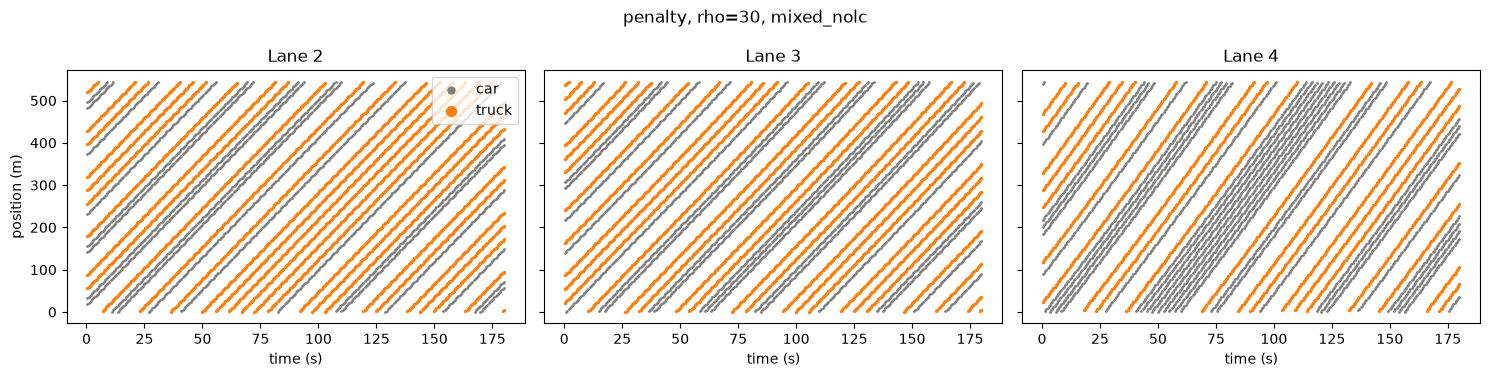

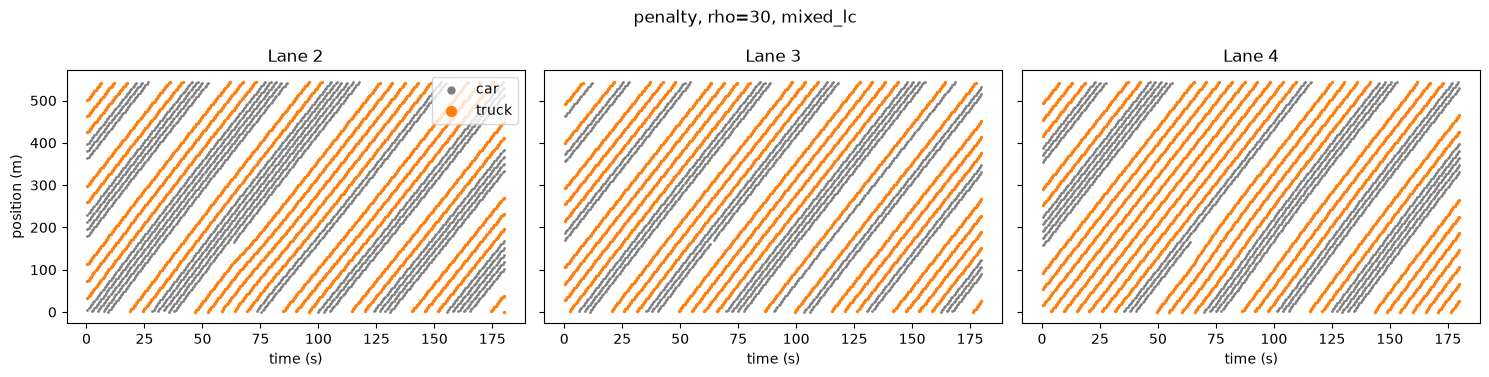

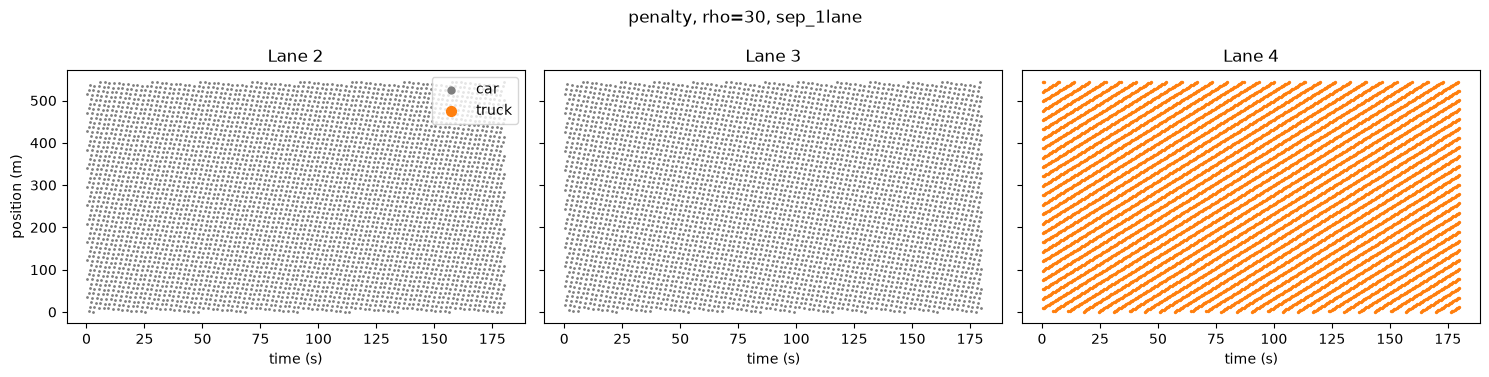

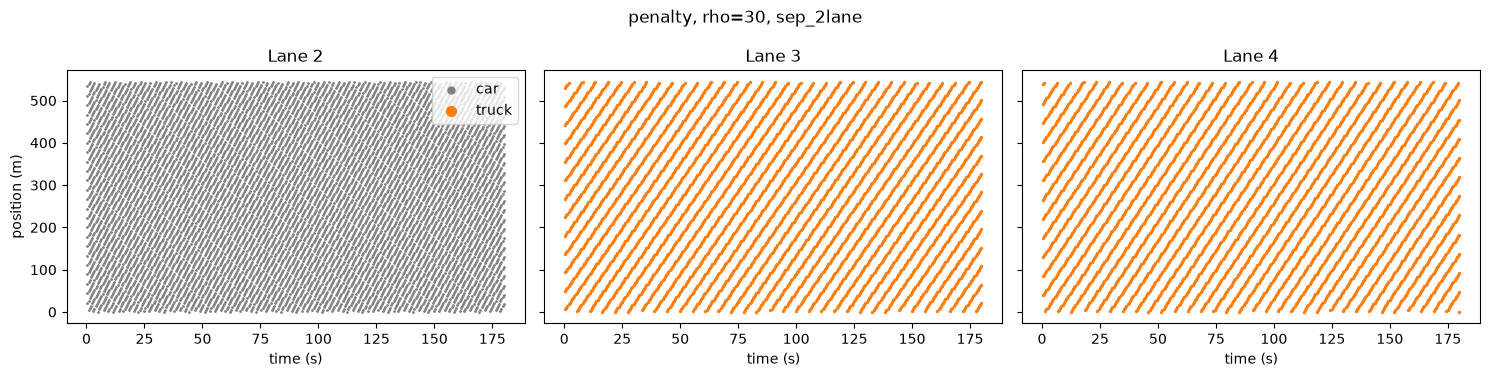

In [16]:
for pol, df_traj in sims_B1.items():
    plot_time_space(df_traj, t_window=(0, 180), title=f'{B1_WORLD}, rho={B1_RHO}, {pol}')

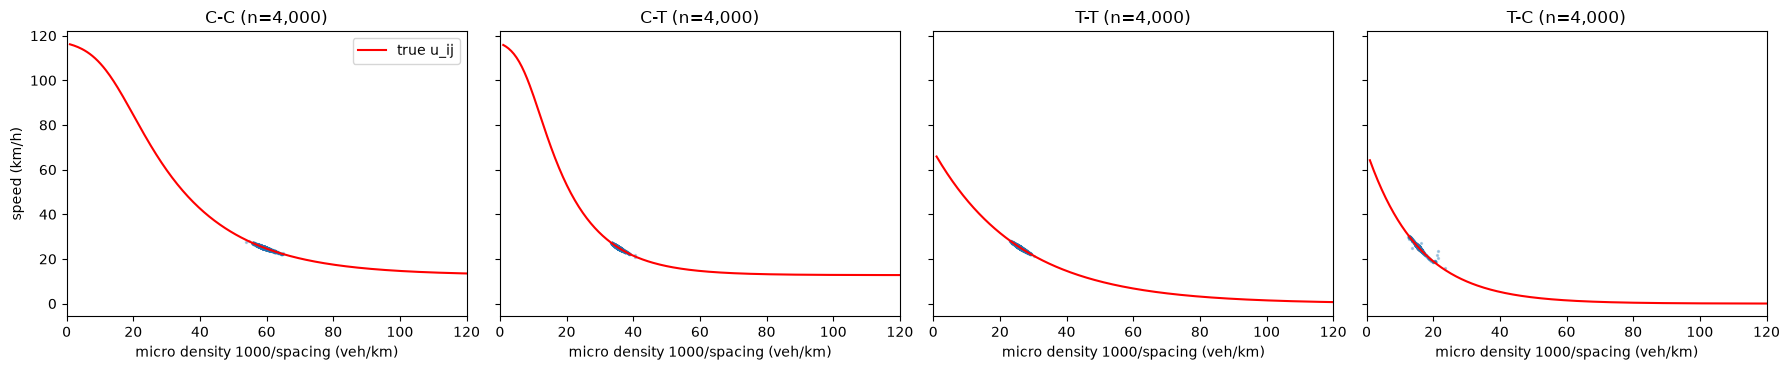

In [17]:
#シミュレータの検証: ミクロ密度-速度が真の u_ij に乗っているか（混走・追い越しありで全4モードが出る）
plot_micro_check(sims_B1['mixed_lc'], B1_WORLD)

In [18]:
rows, res_B1 = [], {}
for pol, df_traj in sims_B1.items():
    _, d = analyze_sim(df_traj, B1_WORLD, eps_kmh=EPS)
    res_B1[pol] = d
    rows.append({'policy': pol, **summarize_regime(d)})
sum_B1 = pd.DataFrame(rows).set_index('policy')

#期待判定（分離は離散配分から、混走は理想的な1-pipe）
exp_B1 = expected_regime_table(B1_WORLD, [B1_RHO], B1_SHARE, [1/3, 2/3], eps=EPS)
exp_map = {'sep_1lane': exp_B1.iloc[0]['regime_expected'], 'sep_2lane': exp_B1.iloc[1]['regime_expected'],
           'mixed_nolc': '1-pipe (ideal)', 'mixed_lc': '1-pipe (ideal) / ?'}
sum_B1.insert(0, 'expected', pd.Series(exp_map))
display(exp_B1.round(3))
sum_B1.round(3)

,world,rho_tot,truck_share,p2_alloc,u_1pipe,p1_star,p2_star,s,u1_sep,u2_sep,regime_expected,lam_equiv
0,penalty,30,0.5,0.333,22.391,0.233,0.517,0.25,77.824,12.079,non-NE,1.736
1,penalty,30,0.5,0.667,22.391,0.233,0.517,0.25,36.454,28.760,2-pipe,0.403


,expected,2-pipe,1-pipe,non-NE,n_snap,coop_exists,s_mean,rho1,rho2,u1_obs,u2_obs,u_1pipe,du1_med,du2_med
policy,,,,,,,,,,,,,,
mixed_nolc,1-pipe (ideal),0.101,0.854,0.046,1800,0.101,0.248,15.045,14.935,23.098,21.886,22.543,0.521,-0.649
mixed_lc,1-pipe (ideal) / ?,0.753,0.247,0.000,1800,0.753,0.247,14.966,15.025,25.106,25.135,22.512,2.648,2.673
sep_1lane,non-NE,0.000,0.000,1.000,1800,0.000,0.250,14.983,14.984,77.867,12.100,22.425,55.427,-10.324
sep_2lane,2-pipe,1.000,0.000,0.000,1800,1.000,0.250,14.985,14.984,36.505,28.778,22.425,13.967,6.244


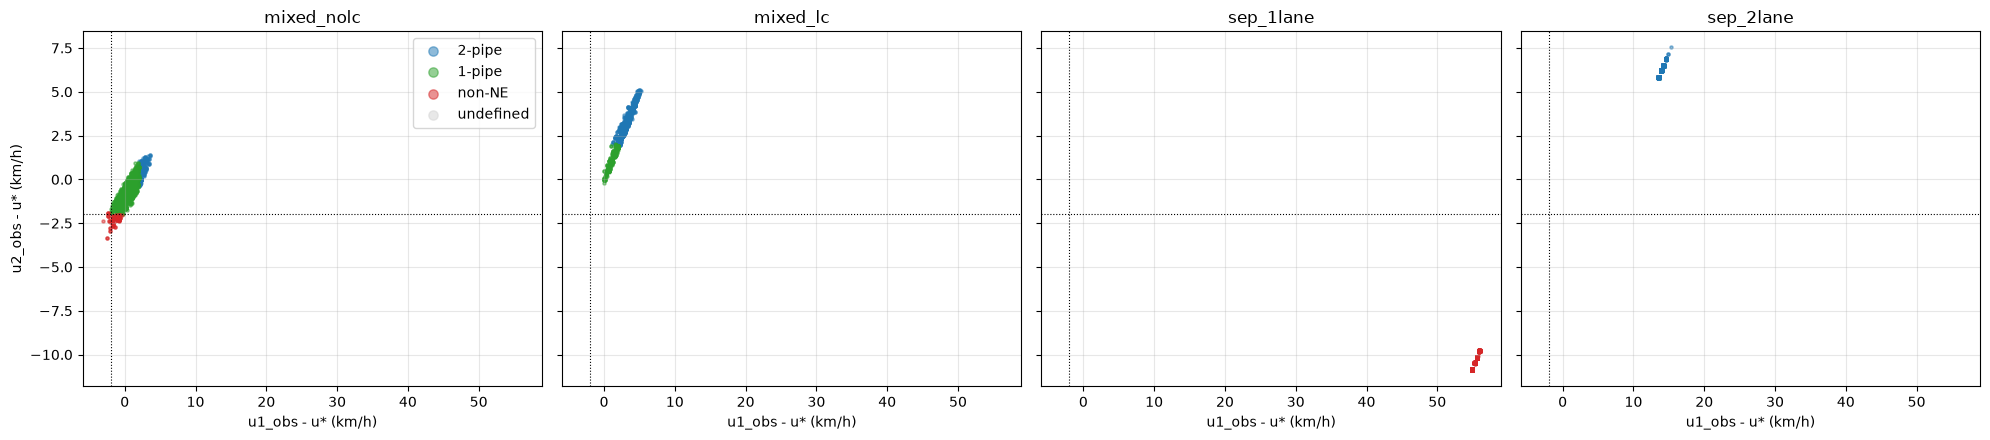

In [19]:
fig, axes = plt.subplots(1, len(res_B1), figsize=(5 * len(res_B1), 4.5), sharex=True, sharey=True)
for ax, (pol, d) in zip(axes, res_B1.items()):
    for r in REGIMES + ['undefined']:
        dd = d[d['regime'] == r]
        ax.scatter(dd['du1'], dd['du2'], s=5, alpha=0.5, color=REGIME_COLORS[r], label=r)
    ax.axvline(-EPS, color='k', lw=0.8, ls=':'); ax.axhline(-EPS, color='k', lw=0.8, ls=':')
    ax.set_title(pol); ax.set_xlabel('u1_obs - u* (km/h)'); ax.grid(alpha=0.3)
axes[0].set_ylabel('u2_obs - u* (km/h)')
axes[0].legend(markerscale=3)
plt.tight_layout()
plt.show()

### B-2. シナリオスイープ: 世界 × 密度 × 車線ルール

スナップショットに必要な 0.5 s 間隔だけ記録して（`record_every=5`）計算を軽くする。
- 混走で 1-pipe、分離で（期待判定どおりなら）2-pipe が出るか
- neutral 世界で 2-pipe / coop_exists がどれだけ出るか（偽陽性）
- 自由流（低密度）の混走がどう判定されるか

In [20]:
SWEEP_WORLDS = ['penalty', 'neutral']
SWEEP_RHOS = [10, 20, 30, 40]
SWEEP_SHARE = 0.5
rows = []
t_start = time.time()
for world in SWEEP_WORLDS:
    for rho in SWEEP_RHOS:
        exp = expected_regime_table(world, [rho], SWEEP_SHARE, [1/3, 2/3], eps=EPS)
        for k, pol in enumerate(POLICY_LIST, start=1):
            df_traj = simulate_ring_road(world, rho, SWEEP_SHARE, policy=pol, record_every=5,
                                         seed=100 + k, verbose=False)
            _, d = analyze_sim(df_traj, world, eps_kmh=EPS)
            expected = {'sep_1lane': exp.iloc[0]['regime_expected'],
                        'sep_2lane': exp.iloc[1]['regime_expected']}.get(pol, '1-pipe (ideal)')
            rows.append({'world': world, 'rho_tot': rho, 'policy': pol, 'expected': expected,
                         's_theory': exp.iloc[0]['s'], **summarize_regime(d)})
print(f"sweep done in {time.time() - t_start:.0f} s")
sweep_B = pd.DataFrame(rows)
sweep_B.round(3)

sweep done in 177 s


,world,rho_tot,policy,expected,s_theory,2-pipe,1-pipe,non-NE,n_snap,coop_exists,s_mean,rho1,rho2,u1_obs,u2_obs,u_1pipe,du1_med,du2_med
0,penalty,10,mixed_nolc,1-pipe (ideal),0.25,0.108,0.436,0.456,1800,0.108,0.245,4.917,4.880,49.666,48.655,50.433,-0.721,-1.679
1,penalty,10,mixed_lc,1-pipe (ideal),0.25,0.050,0.000,0.950,1800,0.050,0.245,4.902,4.890,90.771,43.412,50.407,41.675,-6.958
2,penalty,10,sep_1lane,non-NE,0.25,0.000,0.000,1.000,1800,0.000,0.250,4.892,4.893,111.405,38.881,50.270,61.137,-11.387
3,penalty,10,sep_2lane,2-pipe,0.25,1.000,0.000,0.000,1800,1.000,0.250,4.893,4.895,98.282,51.600,50.263,48.014,1.332
4,penalty,20,mixed_nolc,1-pipe (ideal),0.25,0.204,0.788,0.008,1800,0.204,0.248,10.092,10.080,34.464,34.359,33.422,1.117,0.997
5,penalty,20,mixed_lc,1-pipe (ideal),0.25,0.618,0.377,0.005,1800,0.618,0.247,10.079,10.062,36.054,35.109,33.520,2.359,1.644
6,penalty,20,sep_1lane,non-NE,0.25,0.000,0.000,1.000,1800,0.000,0.250,10.091,10.091,97.139,21.312,33.329,63.543,-12.245
7,penalty,20,sep_2lane,2-pipe,0.25,1.000,0.000,0.000,1800,1.000,0.250,10.092,10.091,59.257,38.187,33.328,25.692,4.637
8,penalty,30,mixed_nolc,1-pipe (ideal),0.25,0.005,0.994,0.001,1800,0.005,0.248,15.142,14.944,22.895,22.725,22.453,0.463,0.244
9,penalty,30,mixed_lc,1-pipe (ideal),0.25,0.894,0.106,0.000,1800,0.894,0.247,15.037,15.023,25.983,26.009,22.473,3.505,3.579


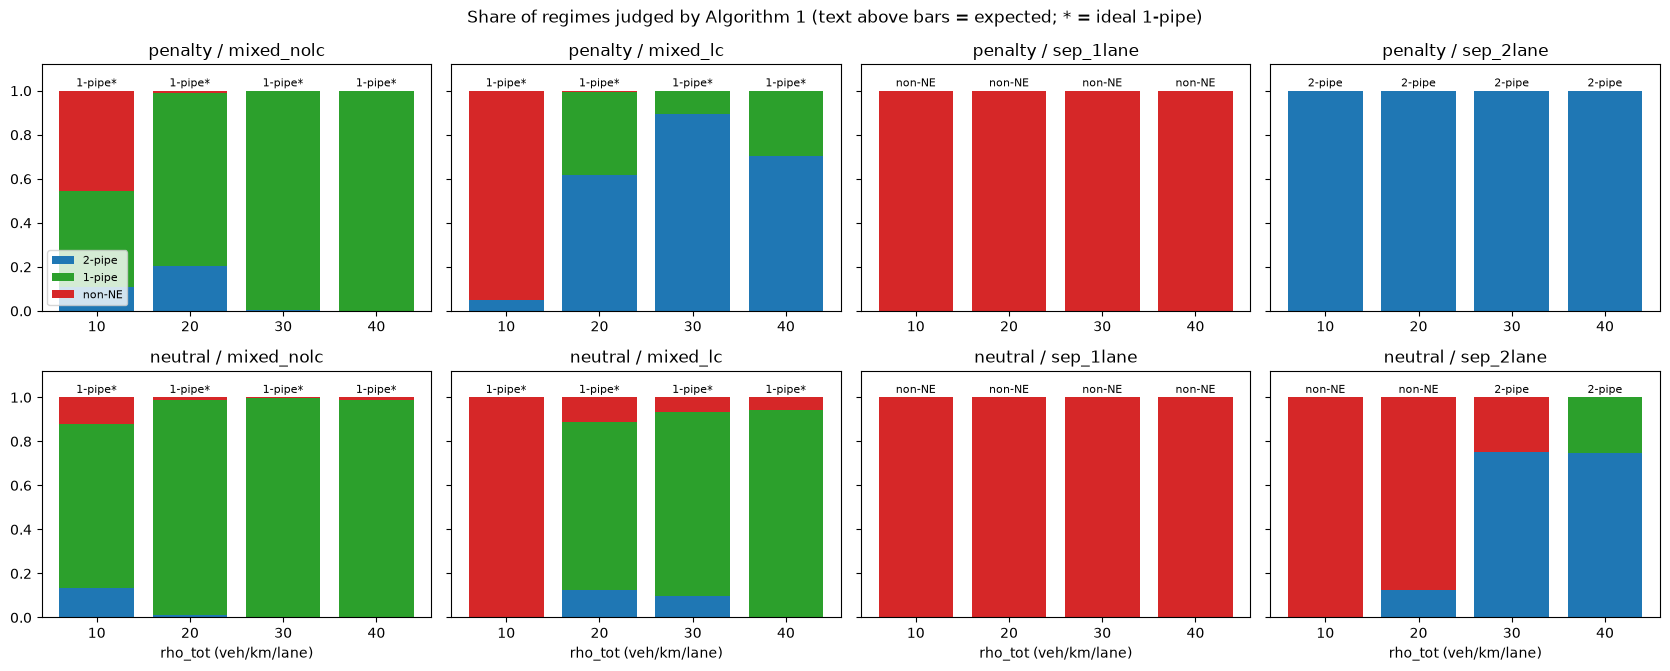

In [21]:
#各セルの判定割合を積み上げ棒で表示
fig, axes = plt.subplots(len(SWEEP_WORLDS), len(POLICY_LIST), figsize=(4.2 * len(POLICY_LIST), 3.4 * len(SWEEP_WORLDS)),
                         sharey=True)
for i, world in enumerate(SWEEP_WORLDS):
    for j, pol in enumerate(POLICY_LIST):
        ax = axes[i, j]
        g = sweep_B[(sweep_B['world'] == world) & (sweep_B['policy'] == pol)].set_index('rho_tot')
        bottom = np.zeros(len(g))
        for r in REGIMES:
            ax.bar(g.index.astype(str), g[r], bottom=bottom, color=REGIME_COLORS[r], label=r)
            bottom += g[r].values
        for xk, (rho, e) in enumerate(g['expected'].items()):
            ax.text(xk, 1.02, e.replace(' (ideal)', '*'), ha='center', fontsize=8)
        ax.set_ylim(0, 1.12)
        ax.set_title(f'{world} / {pol}')
        if i == len(SWEEP_WORLDS) - 1:
            ax.set_xlabel('rho_tot (veh/km/lane)')
axes[0, 0].legend(loc='lower left', fontsize=8)
fig.suptitle('Share of regimes judged by Algorithm 1 (text above bars = expected; * = ideal 1-pipe)')
plt.tight_layout()
plt.show()

## 4. ダミーデータの保存（任意）

NGSIM と同じ「ヘッダなし・空白区切り・18列」で保存すれば、`load_trajectory_data` と同じ読み方で読める。
`time_period` は NGSIM と同様にファイルごとに付け直す想定（ここでは保存しない）。
1ファイルあたり数十MBになるので、デフォルトでは保存しない。

In [22]:
SAVE = False
SAVE_DIR = Path('../data/synthetic')

def save_ngsim_txt(df_traj, path):
    path.parent.mkdir(parents=True, exist_ok=True)
    df_traj[NGSIM_COLUMNS].to_csv(path, sep=' ', header=False, index=False, float_format='%.3f')

def load_synthetic_data(paths):
    #load_trajectory_data と同じ読み方（time_period はファイル順に 1,2,...）
    dfs = []
    for k, p in enumerate(paths, start=1):
        d = pd.read_csv(p, sep=r'\s+', header=None, names=NGSIM_COLUMNS)
        d['time_period'] = k
        dfs.append(d)
    return pd.concat(dfs, ignore_index=True)

if SAVE:
    for pol, df_traj in sims_B1.items():
        save_ngsim_txt(df_traj, SAVE_DIR / f'synthetic_{B1_WORLD}_rho{B1_RHO}_truck{int(B1_SHARE*100)}_{pol}.txt')
    print('saved to', SAVE_DIR.resolve())

## 5. 読み方とメモ

- **期待判定（1章）が「正解」**。Tier B の判定がこれと一致すれば「アルゴリズムは速度パターンを正しく読めている」、ずれれば「その状態はモデルの前提（平衡状態・ランダム混合・道路シェア）から外れている」と解釈する。
- **見た目の分離 ≠ 2-pipe**。分離していても、配分 p2 が [p2\*, p2\*+s] の外なら non-NE になるのが正しい（例: 1:1 でトラックを1車線に押し込むと、トラックが詰まって non-NE）。
- **自由流の混走**は、モデルの 1-pipe（全員が平衡車間で共通速度）が物理的に成立しにくい。追い越し不可だと車線速度がトラックの自由速度に張り付き、ũ1 = ũ2 > ū となるので Eq.11 では 2-pipe と判定されうる。
- **分離シナリオの λ** は、離散配分なので密度によって λ_t = (p1 − p1\*)/s が変わる（`exp_tab['lam_equiv']`）。Step 6 は λ を定数と仮定しているので、Tier B で出る λ̂ は「真値の回復」ではなく誤設定下の挙動として読む。λ の回復性は Tier A（A-4）で評価する。
- 次の拡張候補: トラック比率のスイープ（`SWEEP_SHARE`）、paper 世界の追加、Step 1 も含めた end-to-end（混走キャリブレーション用シナリオで a2, b1 を推定してから分離シナリオに適用）、Eq.7 の inverted 版との比較。